# Revisión de la V18: neuroevolución (MLP entrenado con CEM sobre sus pesos)

Este notebook sirve para **revisar y reproducir** la V18 sin leer todo el código. Usa el código de
`MSAPSO Claude/Modelo Final/Frente_B_neuroevolucion_V18/codigo/` y los resultados guardados en `resultados_V18/`.

**La pregunta.** En la V11 un MLP (*Multi-Layer Perceptron*, red neuronal de capas densas) ubica el pico con 7 mediciones y el CEM
(*Cross-Entropy Method*, método de entropía cruzada) sobre la corriente lo afina. Esa red se entrenó con **retropropagación** (gradientes).
Aquí se entrena la **misma red, con los mismos datos**, de otra forma: cada peso es la media de una distribución, se muestrean muchas redes,
cada una se evalúa por la potencia que logra en las curvas, se conservan las mejores y se vuelve a muestrear. Es decir, el CEM aplicado a los
**pesos de la red** (a esto se le llama *neuroevolución*). ¿Es mejor que la retropropagación? ¿Le gana a los modelos que ya se revisaron?

| Sección | Qué muestra | Tiempo |
|---|---|---|
| 1 | Control: el código de la V18 reproduce exactamente a la V11 cuando se le dan los pesos de la V11 | segundos |
| 2 | Cómo se entrena y qué tan bien aprende cada red | segundos |
| 3 | Qué aprende cada red: dónde predice el pico | segundos |
| 4 | Selección en validación (40 variantes) | lectura de resultados |
| 5 | Prueba estática (sombra fija) | segundos |
| 6 | Prueba dinámica (sombra cambiante) | lectura (o 2–3 min si se recalcula) |
| 7 | Ruido de medición | lectura de resultados |
| 8 | **Comparación con todos los modelos revisados** | segundos |
| 9 | Conclusiones y puntos para revisar | — |

**Glosario rápido.**
*pp* = puntos porcentuales (diferencia entre dos porcentajes de la potencia máxima).
*p99* = el valor que deja por debajo al 99 % de las curvas: el 1 % peor pierde eso o más. El criterio del proyecto es p99 ≤ 3 pp.
*Estático* = una sombra fija y una sola búsqueda. *Dinámico* = la sombra cambia y se mide la energía total entregada.
*MSAPSO* = el enjambre de partículas del paper (175 mediciones). *V7* = el MSAPSO con parada anticipada (70 mediciones), método principal.
*V14* = 3 pasadas del MSAPSO + CEM sobre la corriente + retroceso del 2 %. *V17* = la V14 + verificación por cota física (candidata en dinámico).
*Cota física* = límite de potencia entre dos mediciones (el voltaje no sube al subir la corriente); si podría haber un pico mayor, se mide ahí.
*IC95 %* = intervalo de confianza al 95 % (bootstrap pareado).

**Requisitos:** `numpy scipy numba scikit-learn matplotlib pandas`.

In [1]:
import os, sys, json, re, subprocess, pickle, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

# Ruta al código de la V18 (relativa a la carpeta Notebooks/)
CODIGO = (Path.cwd().parent / "MSAPSO Claude" / "Modelo Final" / "Frente_B_neuroevolucion_V18" / "codigo").resolve()
assert CODIGO.exists(), f"No encuentro {CODIGO}; abre el notebook desde la carpeta Notebooks/"
sys.path.insert(0, str(CODIGO)); os.chdir(CODIGO)        # los resultados se leen con rutas relativas

from neuroevolucion_V18 import Red, PCfg, make_red_cem, make_tables, lookup, cadena, FR, XG
from metodos_V18 import red, metodo, parse
from estatico_V17 import build, final_acc
from mlp_cem_V14 import make_mlp_cem, Cfg as CfgL
from pvsim_V14.static_plant_V14 import StaticPlant

SEL = json.load(open("resultados_V18/seleccion_V18.json"))["elegida"]
CLAVE_SEL, PC_SEL = parse(SEL)
print("Variante congelada (elegida en validación):", SEL)

# Estilo: superficie clara, rejilla tenue, líneas finas. Un color fijo por método (paleta de referencia, orden fijo:
# V7, V14, V17 como en la revisión de la V17; después V11 y V18). MSAPSO y las variantes no destacadas, en gris.
COL = {"V7": "#2a78d6", "V14": "#eb6834", "V17": "#1baf7a", "V11": "#eda100", "V18": "#e87ba4",
       "MSAPSO": "#a3a29b", "gris": "#c3c2b7", "curva": "#a3a29b", "texto": "#0b0b0b", "texto2": "#52514e"}
plt.rcParams.update({"figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c3c2b7",
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False,
    "lines.linewidth": 2, "font.size": 10, "axes.titlesize": 11, "axes.labelcolor": COL["texto2"],
    "xtick.color": COL["texto2"], "ytick.color": COL["texto2"], "legend.frameon": False})

def boot(d, B=3000):
    rb = np.random.default_rng(0); m = d[rb.integers(0, len(d), (B, len(d)))].mean(1)
    return d.mean(), np.percentile(m, 2.5), np.percentile(m, 97.5)
fmt = lambda t: f"{t[0]:+.2f} [{t[1]:+.2f}, {t[2]:+.2f}]"

Variante congelada (elegida en validación): NE 16x16 cola=0 ref=0.1 s0=0.1 +cota


## 1. Control: con los pesos de la V11, el código de la V18 es exactamente la V11

La V18 reimplementa la red en numpy (para poder evaluar cientos de redes a la vez). Si al cargarle los pesos de la V11 no diera lo mismo
que el código original de la V11, cualquier diferencia posterior podría venir de un error de copia y no del entrenamiento.
Se compara en las 1000 curvas S (las de la V14 y la V17) con retroceso del 2 %.

In [2]:
S = build((7777, 7778), 5151)["base 1000 (7777/7778)"][1]
V11_ORIG = make_mlp_cem(pickle.load(open("resultados_V14/mlp_elegido_V11.pkl", "rb")), CfgL(**json.load(open("resultados_V14/seleccion_V11.json"))["mlp_cem"]["cfg"]))
a, na = final_acc(V11_ORIG, S, 0.02)
b, nb_ = final_acc(metodo("V11"), S, 0.02)
print("Exactitud idéntica:", np.allclose(a, b), "| mediciones idénticas:", np.array_equal(na, nb_))

Exactitud idéntica: True | mediciones idénticas: True


## 2. Cómo se entrena y qué tan bien aprende

**Entrenamiento por CEM sobre los pesos** (archivo `neuroevolucion_V18.py`, función `entrenar`):
1. Cada parámetro de la red θᵢ sigue una gaussiana N(μᵢ, σᵢ²). Al inicio μ = 0 y σ es la escala habitual de inicialización.
2. En cada generación se muestrean **200 redes** completas.
3. Cada red se evalúa en un lote de curvas de entrenamiento y recibe un **puntaje de potencia** (no se usa el error contra el pico real).
4. Se conservan las **20 mejores** (élites); μ y σ se mueven hacia su media y su desviación.
5. Se repite **2000 generaciones**. La red final es μ.

**Dos rondas, dos puntajes:**
- **V18** — puntaje = potencia en el punto que predice la red. Resultado: la red aprende a caer sobre *algún* pico con buena potencia,
  pero a menudo no el global, y el refinado posterior (que es local) ya no lo corrige. Ninguna de sus 24 variantes funcionó.
- **V18.1** (revisión escrita antes de abrir la prueba) — puntaje = resultado de la **cadena completa**: barrido de 7 → predicción →
  CEM sobre la corriente → mejor potencia medida. Es exactamente lo que el sistema hará en operación.

Datos: los mismos de la V11 (30 000 curvas sintéticas, semilla 1111). Monitoreo: 2000 curvas distintas (semilla 2222).
La tabla compara la red de la V11 con las 14 redes entrenadas aquí. *Solo red* = la potencia en el punto predicho, sin refinar.
*Cadena* = el resultado después del refinado.

In [3]:
ENT = json.load(open("resultados_V18/entrenamiento_V18.json"))
v11m = ENT["V11 (retropropagacion, 64x64)"]
filas = {"V11 (retropropagación)": {"objetivo": "error contra x*", "parámetros": 4801, **{k: v11m[k] for k in ("potencia_media", "pct_bajo_90", "error_x_medio", "cadena_media", "cadena_bajo_98")}}}
for n, d in ENT["redes"].items():
    filas[n] = {"objetivo": "cadena completa (V18.1)" if "ref=" in n else "potencia en el punto (V18)", "parámetros": d["params"],
                **{k: d["monitoreo"][k] for k in ("potencia_media", "pct_bajo_90", "error_x_medio", "cadena_media", "cadena_bajo_98")}}
t = pd.DataFrame(filas).T
t.columns = ["objetivo", "parámetros", "solo red: potencia media", "solo red: % curvas < 90 %", "error |x̂ − x*|", "cadena: potencia media", "cadena: % curvas < 98 %"]
for c in t.columns[2:]: t[c] = t[c].astype(float).round(3)
display(t)

,objetivo,parámetros,solo red: potencia media,solo red: % curvas < 90 %,error |x̂ − x*|,cadena: potencia media,cadena: % curvas < 98 %
V11 (retropropagación),error contra x*,4801,0.880,41.40,0.057,0.994,9.25
NE 16x16 cola=0,potencia en el punto (V18),433,0.927,27.05,0.116,0.981,18.30
NE 16x16 cola=1,potencia en el punto (V18),433,0.876,51.55,0.111,0.987,16.95
NE 32x32 cola=0,potencia en el punto (V18),1377,0.923,27.55,0.122,0.982,18.10
NE 32x32 cola=1,potencia en el punto (V18),1377,0.852,70.50,0.148,0.984,24.90
NE 64x64 cola=0,potencia en el punto (V18),4801,0.924,27.40,0.121,0.982,18.35
NE 64x64 cola=1,potencia en el punto (V18),4801,0.838,74.85,0.145,0.984,23.90
NE 16x16 cola=0 ref=0.03,cadena completa (V18.1),433,0.814,65.25,0.137,0.980,30.15
NE 16x16 cola=0 ref=0.1,cadena completa (V18.1),433,0.824,61.90,0.103,0.991,14.65
NE 16x16 cola=1 ref=0.03,cadena completa (V18.1),433,0.842,61.15,0.121,0.977,36.65


**Cómo leerla.** Sin refinar, las redes V18 dan más potencia que la V11 (≈ 92 % contra 88 %): optimizaron justo eso.
Pero después del refinado, que es lo que cuenta, la V11 sigue arriba: 99.4 % de potencia media y 9 % de curvas por debajo del 98 %.
La mejor V18.1 llega a 99.1 % con ≈ 15 % de curvas por debajo del 98 %. Entrenar con el puntaje correcto (V18.1) cierra buena parte de la
distancia, pero no toda.

La curva de aprendizaje muestra lo mismo: la red V18 sube rápido en «potencia en el punto» (izquierda), pero en «cadena completa» (derecha)
queda por debajo de la V11. La V18.1 elegida mejora en la cadena y se acerca a la V11 sin alcanzarla.

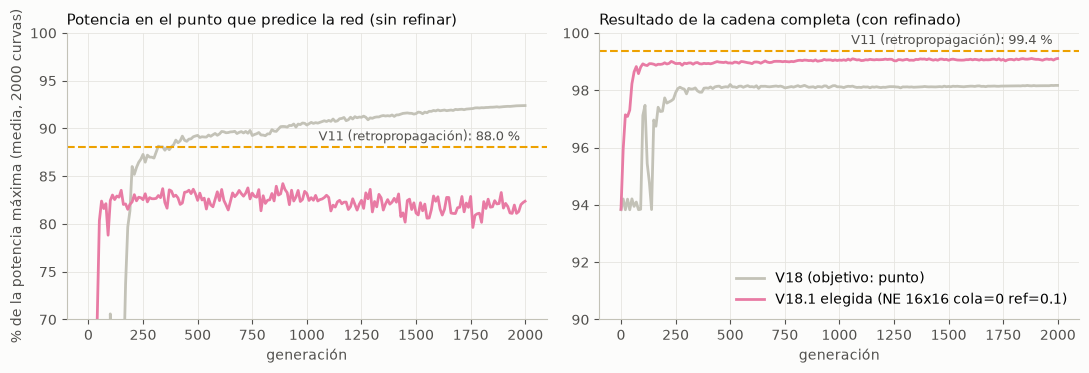

In [4]:
n_v18 = "NE 64x64 cola=0"                   # la red V18 del mismo tamaño que la V11
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, clave, titulo, lim in [(axs[0], "mon", "Potencia en el punto que predice la red (sin refinar)", (70, 100)), (axs[1], "mon_cadena", "Resultado de la cadena completa (con refinado)", (90, 100))]:
    for n, col, lbl in [(n_v18, COL["gris"], "V18 (objetivo: punto)"), (CLAVE_SEL, COL["V18"], f"V18.1 elegida ({CLAVE_SEL})")]:
        L = ENT["redes"][n]["registro"]; ax.plot([l["gen"] for l in L], [100 * l[clave] for l in L], color=col, label=lbl)
    ref = 100 * v11m["potencia_media" if clave == "mon" else "cadena_media"]
    ax.axhline(ref, color=COL["V11"], lw=1.5, ls="--"); ax.annotate(f"V11 (retropropagación): {ref:.1f} %", (2000, ref), xytext=(-4, 5), textcoords="offset points", ha="right", color=COL["texto2"], fontsize=9)
    ax.set_title(titulo, loc="left", color=COL["texto"]); ax.set_xlabel("generación"); ax.set_ylim(*lim)
axs[0].set_ylabel("% de la potencia máxima (media, 2000 curvas)"); axs[1].legend(loc="lower right")
plt.tight_layout(); plt.show()

## 3. Qué aprende cada red: dónde predice el pico

Cada punto es una curva del monitoreo. Eje horizontal: dónde está el pico global (x* = corriente del pico / Isc). Eje vertical: dónde lo predice
la red. Una red perfecta pondría todos los puntos sobre la diagonal punteada.

- **V11**: apunta a x* (lo entrenaron para eso); cuando hay dos picos parecidos, a veces predice un punto intermedio.
- **V18**: casi siempre predice uno de pocos valores fijos (las bandas horizontales en ≈ 0.5 y ≈ 0.93·Isc). Aprendió una regla del tipo
  «elige el pico de corriente media o alta», que da buena potencia en promedio pero ignora dónde está el pico global. Su error contra x* es el doble que el de la V11.
- **V18.1**: un punto medio: sigue la diagonal a grandes rasgos y deja al refinado cerca del pico correcto, pero con más dispersión que la V11
  (y una banda fija en ≈ 0.37·Isc para los picos de corriente baja).

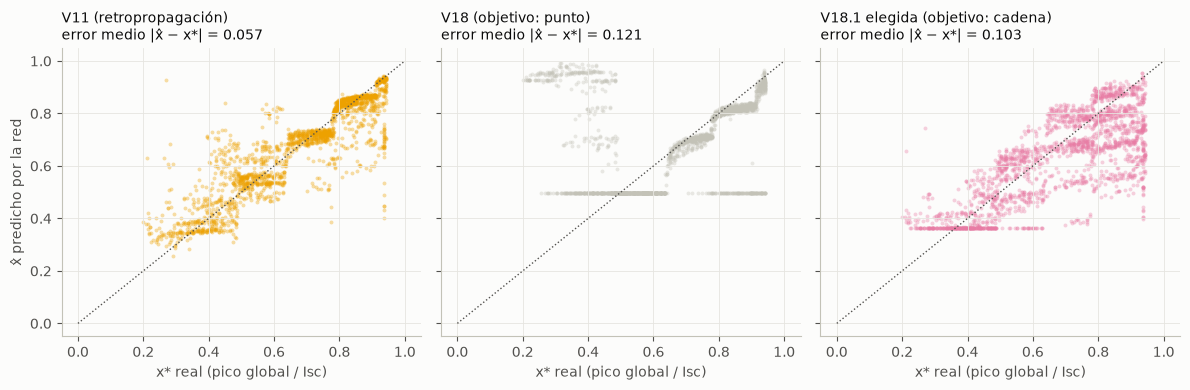

In [5]:
Xm, ym, Tm = make_tables(2000, 2222)
redes = [("V11 (retropropagación)", red("V11"), COL["V11"]), ("V18 (objetivo: punto)", red(n_v18), COL["gris"]), ("V18.1 elegida (objetivo: cadena)", red(CLAVE_SEL), COL["V18"])]
fig, axs = plt.subplots(1, 3, figsize=(12, 4), sharex=True, sharey=True)
for ax, (lbl, r, col) in zip(axs, redes):
    xh = np.clip(r.predict(Xm), 0, 1); err = np.abs(xh - ym).mean()
    ax.scatter(ym, xh, s=8, color=col, alpha=0.35, linewidth=0)
    ax.plot([0, 1], [0, 1], color=COL["texto2"], lw=1, ls=":")
    ax.set_title(f"{lbl}\nerror medio |x̂ − x*| = {err:.3f}", loc="left", color=COL["texto"], fontsize=10)
    ax.set_xlabel("x* real (pico global / Isc)")
axs[0].set_ylabel("x̂ predicho por la red"); plt.tight_layout(); plt.show()

## 4. Selección en validación (40 variantes)

Rejilla: V18 = 6 redes (16×16, 32×32, 64×64; con y sin castigo a la cola) × 4 despliegues (σ0 del refinado 0.03 o 0.1; con o sin la cota de la V17).
V18.1 = 8 redes (16×16 y 64×64; con y sin castigo a la cola; entrenadas con σ0 0.03 o 0.1) × con o sin cota.

**Regla fijada antes de correr** (`diseno_V18.md`): entre las variantes con p99 ≤ 3 pp en los 5 conjuntos estáticos de validación, la de mayor
energía dinámica. **Ninguna pasó el filtro** (la mejor tiene p99 de 11 pp; la V17 tiene 2.4), así que la regla elige la de menor p99:
**red 16×16 entrenada con la cadena completa, σ0 = 0.1, con cota**.

In [6]:
print(open("resultados_V18/seleccion_V18.txt").read())

SELECCION V18 (validacion). p99 max = peor p99 de los 5 conjuntos estaticos (b = 0.02); energia y diferencias: escenarios 600-1199
  variante                             | p99 max | perdida media base | med. | energia - V7 | - V17 | - V11
  NE 16x16 cola=1 ref=0.03 s0=0.03     |   13.87 | +3.001 |  27.8 | +1.66 | -0.20 | +0.63
  NE 16x16 cola=1 ref=0.03 s0=0.03 +cota |   13.49 | +2.383 |  31.1 | +1.63 | -0.23 | +0.60
  NE 16x16 cola=0 ref=0.03 s0=0.03     |   14.32 | +2.643 |  27.8 | +1.51 | -0.35 | +0.48
  NE 16x16 cola=1 s0=0.03              |   28.41 | +3.767 |  27.4 | +1.29 | -0.57 | +0.25
  NE 16x16 cola=0 ref=0.03 s0=0.03 +cota |   13.04 | +2.137 |  30.5 | +1.24 | -0.62 | +0.21
  NE 16x16 cola=1 s0=0.03 +cota        |   28.41 | +2.775 |  31.5 | +1.13 | -0.73 | +0.09
  NE 16x16 cola=1 ref=0.1 s0=0.1       |   12.59 | +1.479 |  38.0 | +1.07 | -0.79 | +0.04
  NE 64x64 cola=1 ref=0.03 s0=0.03     |   21.73 | +2.611 |  27.6 | +1.06 | -0.79 | +0.03
  NE 16x16 cola=0 ref=0.1 s0=0.1     

En la gráfica, cada punto es una variante. Lo ideal es arriba a la izquierda (mucha energía, poca pérdida en el peor caso).
Todas las variantes V18 y V18.1 quedan a la derecha de la línea de 3 pp, y ninguna sube por encima de la V17.

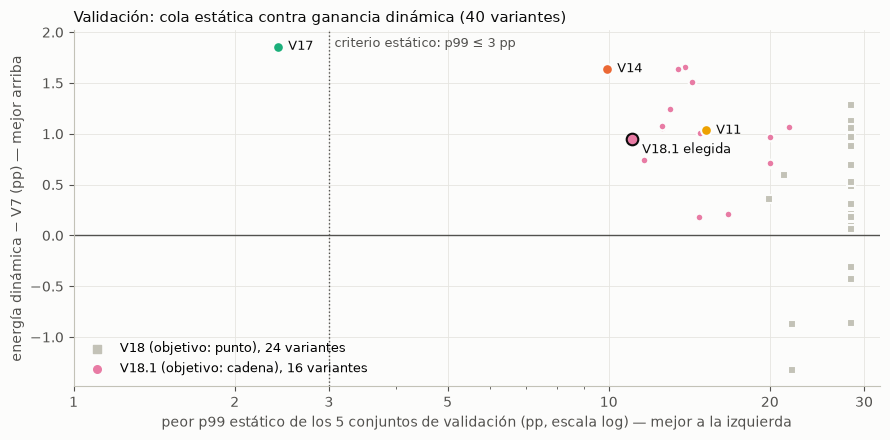

In [7]:
F = json.load(open("resultados_V18/seleccion_V18.json"))["filas"]
Sv = json.load(open("resultados_V18/estatico_val_V18.json")); Dv = json.load(open("resultados_V18/dinamico_val_V18.json"))
conj = sorted({k.split("|")[0] for k in Sv}); Ev = lambda n: np.array([r[n][0] for r in Dv])
fig, ax = plt.subplots(figsize=(9, 4.5))
for f in F:
    v181 = "ref=" in f["variante"]; sel = f["variante"] == SEL
    ax.scatter(f["p99_max"], f["vs_V7"], s=70 if sel else 30, marker="o" if v181 else "s", color=COL["V18"] if v181 else COL["gris"],
               edgecolor=COL["texto"] if sel else "#fcfcfb", linewidth=1.5, zorder=3 if sel else 2)
for r in ("V11", "V14", "V17"):
    x = max(Sv[f"{c}|{r} b=0.02"]["p99"] for c in conj); y = (Ev(r) - Ev("V7")).mean()
    ax.scatter(x, y, s=60, color=COL[r], edgecolor="#fcfcfb", linewidth=1.5, zorder=4)
    ax.annotate(r, (x, y), xytext=(7, 0), textcoords="offset points", va="center", color=COL["texto"], fontsize=9)
f = next(f for f in F if f["variante"] == SEL); ax.annotate("V18.1 elegida", (f["p99_max"], f["vs_V7"]), xytext=(7, -10), textcoords="offset points", color=COL["texto"], fontsize=9)
ax.scatter([], [], s=30, marker="s", color=COL["gris"], label="V18 (objetivo: punto), 24 variantes")
ax.scatter([], [], s=30, marker="o", color=COL["V18"], label="V18.1 (objetivo: cadena), 16 variantes")
ax.axvline(3, color=COL["texto2"], lw=1, ls=":"); ax.axhline(0, color=COL["texto2"], lw=1)
ax.annotate("criterio estático: p99 ≤ 3 pp", (3, ax.get_ylim()[1]), xytext=(4, -12), textcoords="offset points", color=COL["texto2"], fontsize=9)
ax.set_xscale("log"); ax.set_xticks([1, 2, 3, 5, 10, 20, 30]); ax.set_xticklabels(["1", "2", "3", "5", "10", "20", "30"])
ax.set_xlabel("peor p99 estático de los 5 conjuntos de validación (pp, escala log) — mejor a la izquierda")
ax.set_ylabel("energía dinámica − V7 (pp) — mejor arriba")
ax.set_title("Validación: cola estática contra ganancia dinámica (40 variantes)", loc="left", color=COL["texto"])
ax.legend(loc="lower left", fontsize=9); plt.tight_layout(); plt.show()

## 5. Prueba estática (sombra fija)

Pérdida de cada método contra el MSAPSO completo en las 1000 curvas S. V7 sin retroceso; las demás con retroceso del 2 % (como en sus reportes).
La gráfica muestra solo el 10 % peor de las curvas, que es donde está la diferencia.

,mediciones,pérdida media (pp),p95 (pp),p99 (pp),peor caso (pp),% curvas > 3 pp
V7,70.00,0.05,0.23,0.64,0.97,0.0
V11,36.64,1.37,6.46,12.41,21.18,10.9
V14,38.76,0.88,1.91,13.01,22.99,3.7
V17,40.10,0.52,1.04,2.33,3.88,0.3
V18,40.47,1.09,4.46,7.58,14.95,8.9


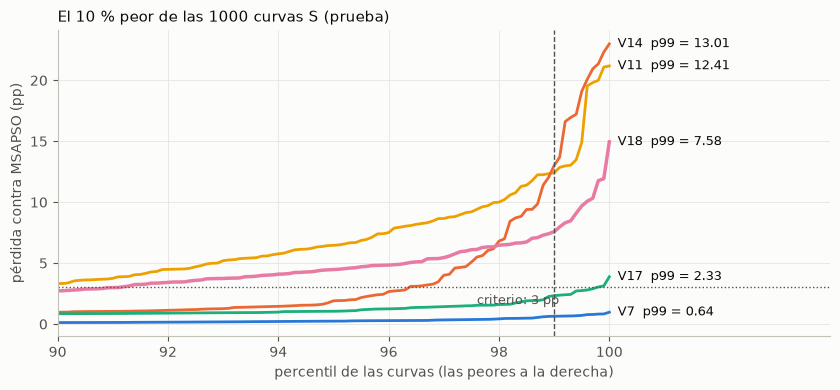

In [8]:
RECALC = {"V7": ("V7", 0.0), "V11": ("V11", 0.02), "V14": ("V14", 0.02), "V17": ("V17", 0.02), "V18": (SEL, 0.02)}
base_S, _ = final_acc(metodo("MSAPSO"), S)
res = {}; med = {}
for m, (n, b) in RECALC.items():
    f, nm = final_acc(metodo(n), S, b); res[m] = base_S - f; med[m] = nm.mean()
tabla = pd.DataFrame({m: {"mediciones": med[m], "pérdida media (pp)": d.mean(), "p95 (pp)": np.percentile(d, 95),
                          "p99 (pp)": np.percentile(d, 99), "peor caso (pp)": d.max(), "% curvas > 3 pp": 100 * np.mean(d > 3)}
                      for m, d in res.items()}).T.round(2)
display(tabla)

fig, ax = plt.subplots(figsize=(8.5, 4))
q = np.linspace(90, 100, 201)
for m, d in res.items():
    y = np.percentile(d, q); ax.plot(q, y, color=COL[m], lw=2.5 if m == "V18" else 2)
    ax.annotate(f"{m}  p99 = {np.percentile(d, 99):.2f}", (100, y[-1]), xytext=(6, 0), textcoords="offset points", va="center", color=COL["texto"], fontsize=9)
ax.axvline(99, color=COL["texto2"], lw=1, ls="--"); ax.axhline(3, color=COL["texto2"], lw=1, ls=":")
ax.annotate("criterio: 3 pp", (97.6, 3), xytext=(0, -12), textcoords="offset points", color=COL["texto2"], fontsize=9)
ax.set_xlabel("percentil de las curvas (las peores a la derecha)"); ax.set_ylabel("pérdida contra MSAPSO (pp)")
ax.set_title("El 10 % peor de las 1000 curvas S (prueba)", loc="left", color=COL["texto"]); ax.set_xlim(90, 104); ax.set_xticks(range(90, 101, 2))
plt.tight_layout(); plt.show()

### Todos los conjuntos estáticos de prueba (resultados guardados)

S y P son los de la V14; 9393/9394 y 5252 son conjuntos que nunca se usaron antes; «reales 4» son los 4 casos del paper.
*Control V11* = la red de la V11 con **el mismo despliegue** que la V18.1 elegida (σ0 = 0.1 y cota): solo cambian los pesos.
Para recalcular: `python3 estatico_V18.py test "<variante>"` desde la carpeta del código (segundos).

In [9]:
def tabla_estatica(archivo):
    d = json.load(open(archivo)); filas = {}
    etiquetas = {"V7 b=0": "V7", "V11 b=0.02": "V11", "V14 b=0.02": "V14", "V17 b=0.02": "V17", f"{SEL} b=0.02": "V18"}
    ctrl = f"V11 s0={PC_SEL.sigma0:g}" + (" +cota" if PC_SEL.cota else "")
    if ctrl != "V11 s0=0.1": etiquetas[f"{ctrl} b=0.02"] = "control V11"
    for key, v in d.items():
        conj, met = key.split("|")
        if met in etiquetas: filas.setdefault(conj, {})[f"p99 {etiquetas[met]}"] = v["p99"]
    t = pd.DataFrame(filas).T.round(2); t["V18 cumple (≤ 3 pp)"] = np.where(t["p99 V18"] <= 3, "sí", "NO"); return t
display(tabla_estatica("resultados_V18/estatico_test_V18.json"))

,p99 V7,p99 V14,p99 V17,p99 V11,p99 control V11,p99 V18,V18 cumple (≤ 3 pp)
base 1000 (7777/7778),0.64,13.01,2.33,12.41,6.14,7.58,NO
72c-6s 100 (5151),0.55,6.42,1.51,8.89,5.46,9.16,NO
36c-3s 100 (5151),0.45,1.38,1.38,13.64,3.97,5.49,NO
60c-11A 100 (5151),0.26,13.18,1.91,14.20,9.05,6.49,NO
96c-6.5A 100 (5151),0.27,10.43,1.93,11.17,5.08,9.17,NO
base 1000 (9393/9394),0.44,10.91,2.02,10.72,4.97,10.50,NO
72c-6s 100 (5252),0.64,12.56,1.57,10.75,9.70,7.45,NO
36c-3s 100 (5252),0.17,1.12,0.71,12.65,3.93,10.57,NO
60c-11A 100 (5252),0.36,4.57,1.65,15.56,8.01,7.16,NO
96c-6.5A 100 (5252),0.33,4.65,1.70,9.51,3.87,6.32,NO


**Lectura.** La V18.1 no cumple el criterio en ningún conjunto sintético (p99 de 5.5 a 10.6 pp) y queda peor que su control V11 en 7 de
los 10 (en S: 7.6 contra 6.1 pp). La excepción son los **4 casos reales del paper**, donde pierde solo 0.6 pp (la V11, 3.3 pp; su control, 2.7 pp); con n = 4 es una
señal, no una conclusión.

## 6. Prueba dinámica (sombra cambiante; escenarios 0–599 y 1200–2399)

Se leen los resultados guardados por escenario y se recalculan las diferencias con IC95 %. Para volver a simular todo, cambia
`RECALCULAR = True` (2–3 min con 22 núcleos; ajusta `Pool(22)` en `dinamico_V18.py` si tienes menos).

In [10]:
RECALCULAR = False
if RECALCULAR:
    subprocess.run([sys.executable, "dinamico_V18.py", "test", SEL], check=True)

from entorno_V14 import make_scenario
R = json.load(open("resultados_V18/dinamico_test_V18.json"))
ctrl = f"V11 s0={PC_SEL.sigma0:g}" + (" +cota" if PC_SEL.cota else ""); ctrl = "V11" if ctrl == "V11 s0=0.1" else ctrl
E = {m: np.array([r[k][0] for r in R]) for m, k in [("MSAPSO", "MSAPSO"), ("V7", "V7"), ("V11", "V11"), ("V14", "V14"), ("V17", "V17"), ("control", ctrl), ("V18", SEL)]}
idx = np.array([r["idx"] for r in R])
filas = {}
for nombre, m in {"prueba 0–599": idx < 600, "confirmación 1200–2399": idx >= 1200}.items():
    filas[nombre] = {"V18 − V7": fmt(boot((E["V18"] - E["V7"])[m])), "V18 − V17": fmt(boot((E["V18"] - E["V17"])[m])),
                     "V18 − control V11 (mismo despliegue)": fmt(boot((E["V18"] - E["control"])[m])),
                     "V11 − V7": fmt(boot((E["V11"] - E["V7"])[m])), "V17 − V7": fmt(boot((E["V17"] - E["V7"])[m])),
                     "% pierde > 3 pp vs MSAPSO (V18)": round(100 * np.mean((E["V18"] - E["MSAPSO"])[m] < -3), 1)}
display(pd.DataFrame(filas).T)

,V18 − V7,V18 − V17,V18 − control V11 (mismo despliegue),V11 − V7,V17 − V7,% pierde > 3 pp vs MSAPSO (V18)
prueba 0–599,"+1.14 [+0.56, +1.76]","-0.59 [-1.10, -0.10]","-0.01 [-0.36, +0.34]","+1.32 [+0.67, +1.97]","+1.74 [+1.33, +2.17]",14.8
confirmación 1200–2399,"+0.85 [+0.39, +1.31]","-0.96 [-1.33, -0.54]","-0.08 [-0.38, +0.22]","+1.31 [+0.82, +1.79]","+1.81 [+1.44, +2.16]",19.1


**Lectura.** La V18.1 sí gana energía contra la V7 (≈ +1 pp, intervalo que no cruza el cero), pero menos que la V17 (≈ −0.6 a −1 pp)
y queda **empatada** con la misma red de la V11 con el mismo despliegue (−0.01 y −0.08 pp; los intervalos cruzan el cero).

### Por tiempo de espera del convertidor (t_wait)

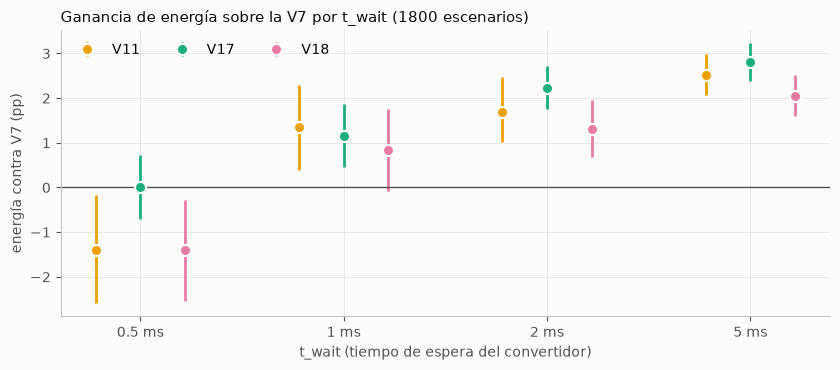

In [11]:
meta = [make_scenario(i)[0] for i in idx]; waits = sorted({x["wait"] for x in meta})
fig, ax = plt.subplots(figsize=(8.5, 3.8)); ms = ["V11", "V17", "V18"]
for j, m in enumerate(ms):
    for i, w in enumerate(waits):
        mm = np.array([x["wait"] == w for x in meta]); mu, lo, hi = boot((E[m] - E["V7"])[mm])
        ax.errorbar(i + (j - 1) * 0.22, mu, yerr=[[mu - lo], [hi - mu]], fmt="o", ms=8, color=COL[m], elinewidth=2, capsize=0,
                    markeredgecolor="#fcfcfb", markeredgewidth=1.5, label=m if i == 0 else None)
ax.axhline(0, color=COL["texto2"], lw=1)
ax.set_xticks(range(len(waits))); ax.set_xticklabels([f"{w * 1e3:g} ms" for w in waits])
ax.set_ylabel("energía contra V7 (pp)"); ax.set_xlabel("t_wait (tiempo de espera del convertidor)")
ax.set_title("Ganancia de energía sobre la V7 por t_wait (1800 escenarios)", loc="left", color=COL["texto"])
ax.legend(loc="upper left", ncol=3); plt.tight_layout(); plt.show()

A 0.5 ms (el t_wait del paper) la V18.1 pierde contra la V7 (−1.4 pp): es la única «debilidad» del desglose y es peor que el límite de −1 pp
del criterio 3. Además pierde más de 3 pp contra el MSAPSO en 15–19 % de los escenarios (límite: 10 %). El desglose completo está en
`resultados_V18/dinamico_test_V18.txt`.

## 7. Ruido de medición

Reporte adicional, sin criterio (como en la V17). Con ruido de 1 y 2 W en la potencia medida.

In [12]:
t1 = tabla_estatica("resultados_V18/estatico_test_ruido1_V18.json").add_suffix(" · 1 W")
t2 = tabla_estatica("resultados_V18/estatico_test_ruido2_V18.json").add_suffix(" · 2 W")
cols = [c for c in list(t1.columns) + list(t2.columns) if any(k in c for k in ("V7", "V17", "V18")) and "cumple" not in c]
display(pd.concat([t1, t2], axis=1)[cols])

,p99 V7 · 1 W,p99 V17 · 1 W,p99 V18 · 1 W,p99 V7 · 2 W,p99 V17 · 2 W,p99 V18 · 2 W
base 1000 (7777/7778),1.44,3.96,7.78,1.76,5.78,9.47
72c-6s 100 (5151),0.89,1.89,6.74,1.96,5.13,6.75
36c-3s 100 (5151),1.79,9.22,9.00,2.49,8.49,16.79
60c-11A 100 (5151),0.99,2.97,11.53,1.20,3.66,9.53
96c-6.5A 100 (5151),1.00,3.01,10.87,2.04,3.60,9.16
base 1000 (9393/9394),0.80,3.88,7.97,1.68,5.85,9.22
72c-6s 100 (5252),0.84,3.30,7.49,1.78,3.14,6.21
36c-3s 100 (5252),1.00,7.75,10.21,1.16,9.50,24.96
60c-11A 100 (5252),0.61,3.01,8.93,0.80,3.67,7.11
96c-6.5A 100 (5252),0.57,2.87,6.61,0.69,3.72,6.36


## 8. Comparación con todos los modelos revisados

Las filas de MSAPSO, V7, V11, V14, V17 y V18.1 se **recalcularon aquí con exactamente los mismos conjuntos y escenarios de prueba**.
Las de V10 (CEM puro), V15 (DGBCO) y V16 (CEDGO) se toman del *Resumen consolidado V2–V16*: su código no está en el repositorio y sus cifras
vienen de sus propias campañas, así que sirven como orientación, no como comparación exacta.
*Energía dinámica − V7* = diferencia media en los 1800 escenarios de prueba y confirmación, con IC95 %.

In [13]:
St = json.load(open("resultados_V18/estatico_test_V18.json")); S_key = "base 1000 (7777/7778)"
reales_key = "reales 4 (casos del paper)"
mets = [("MSAPSO completo", "MSAPSO", None), ("V7 (parada anticipada)", "V7", "V7 b=0"), ("V11 (MLP retropropagación + CEM)", "V11", "V11 b=0.02"),
        ("V14 (MSAPSO corto + CEM + 2 %)", "V14", "V14 b=0.02"), ("V17 (V14 + cota física)", "V17", "V17 b=0.02"), ("V18.1 (MLP por CEM sobre pesos + CEM)", "V18", f"{SEL} b=0.02")]
filas = {}
for lbl, m, k in mets:
    st = St[f"{S_key}|{k}"] if k else dict(med=175.0, p99=0.0, media=0.0)
    re_ = St[f"{reales_key}|{k}"]["media"] if k else 0.0
    filas[lbl] = {"entrenamiento": "sí" if m in ("V11", "V18") else "no", "mediciones (S)": round(st["med"], 1),
                  "pérdida estática media (pp)": round(st["media"], 2), "p99 estático S (pp)": round(st["p99"], 2),
                  "pérdida en los 4 casos reales (pp)": round(re_, 2),
                  "energía dinámica − V7 (pp)": "0 (referencia)" if m == "V7" else fmt(boot(E[m] - E["V7"])),
                  "fuente": "recalculado aquí"}
REPORTADOS = {
    "V10 (CEM puro)": {"entrenamiento": "no", "mediciones (S)": "≈ 40–70", "pérdida estática media (pp)": "0.9–1.5", "p99 estático S (pp)": "—",
                       "pérdida en los 4 casos reales (pp)": "—", "energía dinámica − V7 (pp)": "−0.92", "fuente": "Resumen consolidado V2–V16"},
    "V15 (DGBCO, 40 med.)": {"entrenamiento": "no", "mediciones (S)": "40", "pérdida estática media (pp)": "—", "p99 estático S (pp)": "16",
                             "pérdida en los 4 casos reales (pp)": "—", "energía dinámica − V7 (pp)": "+0.8", "fuente": "Resumen consolidado V2–V16"},
    "V16 (CEDGO, 40 med.)": {"entrenamiento": "no", "mediciones (S)": "40", "pérdida estática media (pp)": "—", "p99 estático S (pp)": "28.9",
                             "pérdida en los 4 casos reales (pp)": "—", "energía dinámica − V7 (pp)": "−0.89 / −0.81", "fuente": "Resumen consolidado V2–V16"},
}
display(pd.DataFrame({**filas, **REPORTADOS}).T)

,entrenamiento,mediciones (S),pérdida estática media (pp),p99 estático S (pp),pérdida en los 4 casos reales (pp),energía dinámica − V7 (pp),fuente
MSAPSO completo,no,175.0,0.0,0.0,0.0,"-2.85 [-3.16, -2.53]",recalculado aquí
V7 (parada anticipada),no,70.0,0.05,0.64,0.04,0 (referencia),recalculado aquí
V11 (MLP retropropagación + CEM),sí,36.6,1.37,12.41,3.34,"+1.31 [+0.93, +1.70]",recalculado aquí
V14 (MSAPSO corto + CEM + 2 %),no,38.8,0.88,13.01,0.38,"+1.52 [+1.24, +1.81]",recalculado aquí
V17 (V14 + cota física),no,40.1,0.52,2.33,0.38,"+1.79 [+1.51, +2.06]",recalculado aquí
V18.1 (MLP por CEM sobre pesos + CEM),sí,40.5,1.09,7.58,0.58,"+0.95 [+0.57, +1.33]",recalculado aquí
V10 (CEM puro),no,≈ 40–70,0.9–1.5,—,—,−0.92,Resumen consolidado V2–V16
"V15 (DGBCO, 40 med.)",no,40,—,16,—,+0.8,Resumen consolidado V2–V16
"V16 (CEDGO, 40 med.)",no,40,—,28.9,—,−0.89 / −0.81,Resumen consolidado V2–V16


La gráfica resume el compromiso de todo el proyecto: el eje horizontal es el riesgo con sombra fija (p99, escala log; la zona gris es la
aceptable) y el vertical, la ganancia con sombra cambiante. **Solo la V7 y la V17 están en la zona aceptable, y la V17 además gana energía.**
La V18.1 cae en el mismo grupo que V11 y V14: gana energía, pero con una cola de fallos con sombra fija que no se acepta.

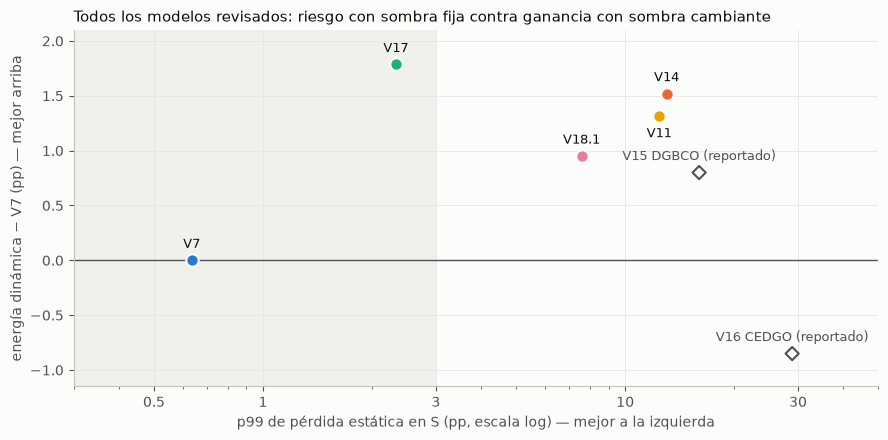

In [14]:
pts = [("V7", St[f"{S_key}|V7 b=0"]["p99"], 0.0), ("V11", St[f"{S_key}|V11 b=0.02"]["p99"], boot(E["V11"] - E["V7"])[0]),
       ("V14", St[f"{S_key}|V14 b=0.02"]["p99"], boot(E["V14"] - E["V7"])[0]), ("V17", St[f"{S_key}|V17 b=0.02"]["p99"], boot(E["V17"] - E["V7"])[0]),
       ("V18", St[f"{S_key}|{SEL} b=0.02"]["p99"], boot(E["V18"] - E["V7"])[0])]
rep = [("V15 DGBCO (reportado)", 16.0, 0.8), ("V16 CEDGO (reportado)", 28.9, -0.85)]
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.axvspan(0.3, 3, color="#e6e5e0", alpha=0.5, lw=0); ax.annotate("zona aceptable: p99 ≤ 3 pp", (0.32, 2.4), color=COL["texto2"], fontsize=9)
for lbl, x, y in rep:
    ax.scatter(x, y, s=45, marker="D", facecolor="none", edgecolor=COL["texto2"], linewidth=1.5, zorder=3)
    ax.annotate(lbl, (x, y), xytext=(0, 9), textcoords="offset points", ha="center", color=COL["texto2"], fontsize=9)
for m, x, y in pts:
    ax.scatter(x, y, s=80, color=COL[m], edgecolor="#fcfcfb", linewidth=1.5, zorder=4)
    ax.annotate("V18.1" if m == "V18" else m, (x, y), xytext=(0, -15) if m == "V11" else (0, 9), textcoords="offset points", ha="center", color=COL["texto"], fontsize=9)
ax.axhline(0, color=COL["texto2"], lw=1)
ax.set_ylim(-1.15, 2.1); ax.set_xscale("log"); ax.set_xlim(0.3, 50); ax.set_xticks([0.5, 1, 3, 10, 30]); ax.set_xticklabels(["0.5", "1", "3", "10", "30"])
ax.set_xlabel("p99 de pérdida estática en S (pp, escala log) — mejor a la izquierda")
ax.set_ylabel("energía dinámica − V7 (pp) — mejor arriba")
ax.set_title("Todos los modelos revisados: riesgo con sombra fija contra ganancia con sombra cambiante", loc="left", color=COL["texto"])
plt.tight_layout(); plt.show()

## 9. Conclusiones

1. **Neuroevolución contra retropropagación (misma red, mismos datos, mismo despliegue): la retropropagación gana.** Con el puntaje correcto
   (cadena completa, V18.1), el CEM sobre los pesos llega al mismo nivel de energía dinámica que la V11 (−0.01 y −0.08 pp, sin diferencia
   demostrable), pero su cola estática es peor en 7 de 10 conjuntos sintéticos (en S, p99 de 7.6 contra 6.1 pp). No es mejor.
   El supuesto del diseño de la V11 («lo supervisado es la cota superior de ES/RL») se sostiene en la práctica para esta red.
2. **Lo que sí aporta la neuroevolución:** puede optimizar directamente un objetivo no diferenciable (la potencia final). Con el puntaje
   equivocado (V18) aprendió algo inútil para el sistema; la lección es que **hay que puntuar la cadena completa**, no un paso intermedio.
3. **Contra los modelos revisados:** no supera a la V17 en nada medido (energía −0.6 a −1 pp; p99 estático 5.5–10.5 pp contra ≤ 2.3 pp;
   necesita entrenamiento). Cumple solo el criterio 2 (gana energía a la V7). **La V17 sigue siendo la candidata en dinámico y la V7 el
   método principal.**
4. **Señal a vigilar:** en los 4 casos reales del paper la V18.1 pierde solo 0.6 pp en estático. Con 4 curvas no alcanza para concluir,
   y en dinámico con curvas reales no se repite (−1.1 pp contra la V7).

## Puntos para revisar

- [ ] **Sección 1:** el código de la V18 con los pesos de la V11 da exactamente lo mismo que la V11.
- [ ] **Sección 2:** el entrenamiento converge (curvas planas al final) y el puntaje V18.1 mejora la cadena respecto a V18.
- [ ] **Sección 4:** ninguna variante pasa el filtro estático; la elegida sale de la regla fijada antes de correr.
- [ ] **Secciones 5–6:** veredicto contra los criterios (tabla en `README_V18.md`).
- [ ] **Código** (`neuroevolucion_V18.py`): `entrenar` (CEM sobre los pesos), `cadena` (simulación vectorizada del refinado; se comprobó
      que coincide con la planta real: 0.9922 contra 0.9924 de potencia media en 300 curvas), `make_red_cem` (el despliegue).
- [ ] **Supuestos a discutir:**
    - la red se entrena solo con el panel base (como la V11) y se prueba en 5 paneles;
    - el entrenamiento usa curvas sin ruido; en operación el barrido sí tiene ruido;
    - el puntaje con castigo a la cola, el número de generaciones y el puntaje de cadena se fijaron tras un piloto (V18) y una ronda de validación (V18.1);
    - los escenarios de validación ya se habían usado en la V14 y la V17.
- [ ] **Siguiente paso posible (no probado):** entrenar con ruido en el barrido y con varios paneles; o usar la red solo como «segunda opinión»
      dentro de la V17 (por ejemplo, para decidir dónde sondear), en lugar de como buscador.

Documentos: `README_V18.md` (veredicto) y `diseno_V18.md` (criterios y revisiones), en `MSAPSO Claude/Modelo Final/Frente_B_neuroevolucion_V18/`.